# Random Forest — Other Areas Model

This notebook predicts **`LSOA GVA Estimates (millions)`** for LSOAs outside Swindon.

It uses the same predictors and evaluation framework as the Swindon internal model, allowing a consistent comparison between Swindon and the wider reference areas.

Feature importance reflects predictive association rather than causation.

In [7]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")

OUTPUT_DIR = Path("../outputs/rf_other")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_features = pd.read_csv("../data/features.csv")
df_names = pd.read_csv("../data/Swindon LSOA local names.csv")

df_features_clean = df_features.drop_duplicates(
    subset=["LSOA21CD"],
    keep="first"
)

swindon_codes = set(df_names["LSOA21CD"])

df_other = df_features_clean[
    ~df_features_clean["LSOA21CD"].isin(swindon_codes)
].copy()

df_other["Local LSOA21 Name"] = df_other["LSOA21NM"]

print("Other-area rows:", len(df_other))
display(df_other.head())

Other-area rows: 985


,LSOA21CD,LSOA21NM,LSOA21NMW,RUC21CD,RUC21NM,Urban_rura,Shape_Leng,Shape__Are,Shape__Len,MSOA21CD,...,share_enterprises_kibs_2025_msoa,share_enterprises_anchor_2025_msoa,enterprises_per_1k_residents_2025,share_enterprises_public_2025_msoa,share_enterprises_private_2025_msoa,bus_stop_count,area_km2,bus_stop_density,dist_to_primary_m,Local LSOA21 Name
110,E01016180,Bracknell Forest 005A,NaN,UN1,Urban: Nearer to a major town or city,Urban,3818.191526,5.232585e+05,3818.191526,E02003356,...,0.500000,0.068966,213.235294,0.0,1.0,4,1.343901,2.976409,227.840465,Bracknell Forest 005A
111,E01016181,Bracknell Forest 005B,NaN,UN1,Urban: Nearer to a major town or city,Urban,20325.254620,1.526824e+07,20325.254621,E02003356,...,0.500000,0.068966,146.686899,0.0,1.0,3,39.177783,0.076574,255.951156,Bracknell Forest 005B
112,E01016182,Bracknell Forest 005C,NaN,UN1,Urban: Nearer to a major town or city,Urban,5034.969100,1.055009e+06,5034.969100,E02003356,...,0.500000,0.068966,186.495177,0.0,1.0,2,2.710765,0.737799,1309.306096,Bracknell Forest 005C
113,E01016183,Bracknell Forest 005D,NaN,UN1,Urban: Nearer to a major town or city,Urban,2689.626323,2.552390e+05,2689.626323,E02003356,...,0.500000,0.068966,215.293244,0.0,1.0,1,0.655629,1.525253,626.091042,Bracknell Forest 005D
114,E01016185,Bracknell Forest 002B,NaN,UN1,Urban: Nearer to a major town or city,Urban,7597.510898,1.111922e+06,7597.510898,E02003353,...,0.438849,0.050360,491.861288,0.0,1.0,8,2.856764,2.800371,976.202911,Bracknell Forest 002B


In [8]:
target = "LSOA GVA Estimates (millions)"

level4_feature = 'Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %'

candidate_features = ['IMD_decile', 'VOA_total_RV_pct_change', 'employment_rate_per_pop', 'LU_pct_micro_2025_msoa', 'LU_pct_large_2025_msoa', 'full_to_part_ratio', 'LU_diversity_1-HHI_2025', 'share_enterprises_green_aligned_2025_msoa', 'share_enterprises_kibs_2025_msoa', 'share_enterprises_creative_2025_msoa', 'share_enterprises_industrial_2025_msoa', 'share_enterprises_foundational_2025_msoa', 'No qualifications %', 'Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %', 'Average download speed (Mbit/s)', 'bus_stop_density', 'enterprises_per_1k_residents_2025', 'dist_to_primary_m']

features = [
    feature for feature in candidate_features
    if feature in df_other.columns
]

model_df = df_other.dropna(
    subset=[target, "MSOA21CD"]
).copy()

X = model_df[features].replace(
    [np.inf, -np.inf],
    np.nan
)

y = model_df[target].astype(float)
groups = model_df["MSOA21CD"]

print("Model rows:", len(model_df))
print("Unique MSOA groups:", groups.nunique())
print("Predictors:", len(features))
print(features)

Model rows: 897
Unique MSOA groups: 196
Predictors: 18
['IMD_decile', 'VOA_total_RV_pct_change', 'employment_rate_per_pop', 'LU_pct_micro_2025_msoa', 'LU_pct_large_2025_msoa', 'full_to_part_ratio', 'LU_diversity_1-HHI_2025', 'share_enterprises_green_aligned_2025_msoa', 'share_enterprises_kibs_2025_msoa', 'share_enterprises_creative_2025_msoa', 'share_enterprises_industrial_2025_msoa', 'share_enterprises_foundational_2025_msoa', 'No qualifications %', 'Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %', 'Average download speed (Mbit/s)', 'bus_stop_density', 'enterprises_per_1k_residents_2025', 'dist_to_primary_m']


In [9]:
def make_model():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        (
            "rf",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=6,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features=0.8,
                bootstrap=True,
                random_state=42,
                n_jobs=1
            )
        )
    ])

    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False
    )

cv = GroupKFold(n_splits=5)

oof = pd.Series(index=X.index, dtype=float)
fold_rows = []
importance_arrays = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    model = make_model()
    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    predictions_fold = model.predict(
        X.iloc[test_idx]
    )

    oof.loc[X.index[test_idx]] = predictions_fold

    fold_rows.append({
        "Fold": fold,
        "Training_rows": len(train_idx),
        "Test_rows": len(test_idx),
        "MAE": mean_absolute_error(
            y.iloc[test_idx],
            predictions_fold
        ),
        "MedianAE": median_absolute_error(
            y.iloc[test_idx],
            predictions_fold
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y.iloc[test_idx],
                predictions_fold
            )
        ),
        "R2": r2_score(
            y.iloc[test_idx],
            predictions_fold
        )
    })

    importance_result = permutation_importance(
        model,
        X.iloc[test_idx],
        y.iloc[test_idx],
        n_repeats=5,
        random_state=42 + fold,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    importance_arrays.append(
        importance_result.importances_mean
    )

fold_metrics = pd.DataFrame(fold_rows)
display(fold_metrics.round(3))

,Fold,Training_rows,Test_rows,MAE,MedianAE,RMSE,R2
0,1,717,180,45.064,6.135,250.583,0.285
1,2,717,180,31.026,7.332,69.547,0.748
2,3,718,179,28.374,6.007,83.977,0.561
3,4,718,179,49.023,5.575,188.709,0.395
4,5,718,179,67.909,7.840,322.489,0.272


In [10]:
largest_idx = y.idxmax()
largest_name = model_df.loc[
    largest_idx,
    "Local LSOA21 Name"
]
without_largest = y.index != largest_idx

overall_metrics = pd.DataFrame([
    {
        "Sample": "All observed Other-area LSOAs",
        "N": len(y),
        "MAE": mean_absolute_error(y, oof),
        "MedianAE": median_absolute_error(y, oof),
        "RMSE": np.sqrt(mean_squared_error(y, oof)),
        "R2": r2_score(y, oof)
    },
    {
        "Sample": (
            "Without largest GVA outlier "
            f"({largest_name})"
        ),
        "N": int(without_largest.sum()),
        "MAE": mean_absolute_error(
            y[without_largest],
            oof[without_largest]
        ),
        "MedianAE": median_absolute_error(
            y[without_largest],
            oof[without_largest]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y[without_largest],
                oof[without_largest]
            )
        ),
        "R2": r2_score(
            y[without_largest],
            oof[without_largest]
        )
    }
])

importance_df = pd.DataFrame({
    "Feature": features,
    "Mean_permutation_importance": np.mean(
        importance_arrays,
        axis=0
    ),
    "Between_fold_SD": np.std(
        importance_arrays,
        axis=0
    )
}).sort_values(
    "Mean_permutation_importance",
    ascending=False
)

predictions = model_df[
    [
        "LSOA21CD",
        "MSOA21CD",
        "Local LSOA21 Name"
    ]
].copy()

predictions["Actual_GVA"] = y
predictions["Predicted_GVA"] = oof
predictions["Residual"] = y - oof
predictions["Absolute_error"] = (
    predictions["Residual"].abs()
)

display(overall_metrics.round(3))
display(importance_df.head(15).round(3))
display(
    predictions
    .nlargest(10, "Absolute_error")
    .round(3)
)

,Sample,N,MAE,MedianAE,RMSE,R2
0,All observed Other-area LSOAs,897,44.265,6.704,206.973,0.342
1,Without largest GVA outlier (Reading 019B),896,40.233,6.694,167.206,0.369


,Feature,Mean_permutation_importance,Between_fold_SD
2,employment_rate_per_pop,43.390,6.548
3,LU_pct_micro_2025_msoa,0.635,0.467
5,full_to_part_ratio,0.594,0.394
4,LU_pct_large_2025_msoa,0.450,0.452
1,VOA_total_RV_pct_change,0.225,0.394
11,share_enterprises_foundational_2025_msoa,0.111,0.124
16,enterprises_per_1k_residents_2025,0.078,0.127
12,No qualifications %,0.036,0.145
13,"Level 4 qualifications or above: degree (BA, B...",0.030,0.361
9,share_enterprises_creative_2025_msoa,-0.005,0.739


,LSOA21CD,MSOA21CD,Local LSOA21 Name,Actual_GVA,Predicted_GVA,Residual,Absolute_error
1017,E01033415,E02006939,Reading 019B,4407.307,750.040,3657.267,3657.267
396,E01016486,E02003408,Slough 002D,3579.158,385.782,3193.376,3193.376
694,E01028521,E02005947,Oxford 008A,2349.570,463.930,1885.640,1885.640
580,E01016684,E02003441,Wokingham 003D,1391.787,18.927,1372.860,1372.860
408,E01016499,E02003409,Slough 003G,1406.197,191.325,1214.872,1214.872
500,E01016594,E02003427,Windsor and Maidenhead 007E,1363.765,312.744,1051.021,1051.021
581,E01016685,E02003441,Wokingham 003E,1391.787,347.544,1044.243,1044.243
230,E01016311,E02003378,West Berkshire 012B,908.411,162.608,745.803,745.803
586,E01016690,E02003455,Wokingham 017C,783.651,44.068,739.583,739.583
167,E01016242,E02003355,Bracknell Forest 004D,1253.169,528.950,724.219,724.219


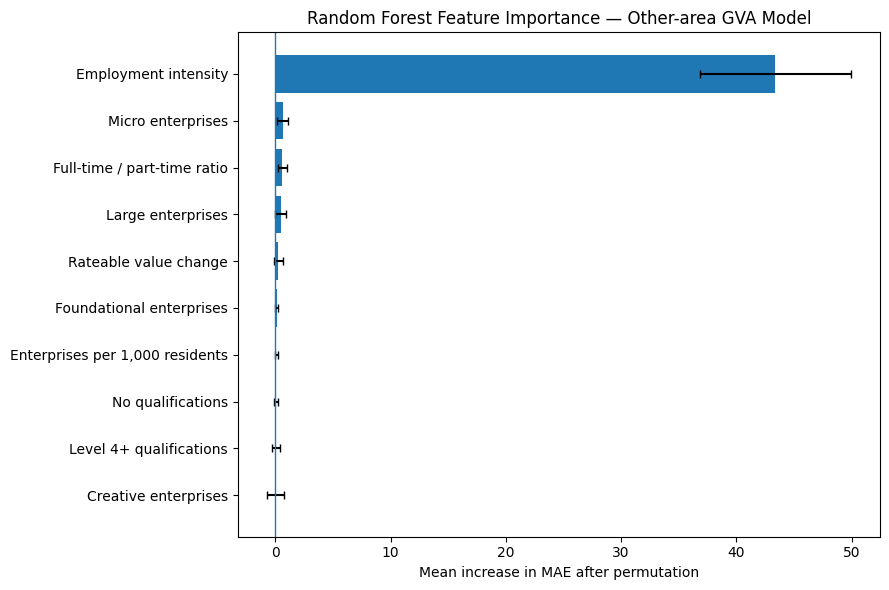

In [11]:
short_names = {
    "employment_rate_per_pop": "Employment intensity",
    "LU_diversity_1-HHI_2025": "Enterprise diversity",
    "IMD_decile": "IMD decile",
    "share_enterprises_foundational_2025_msoa": "Foundational enterprises",
    "Average download speed (Mbit/s)": "Download speed",
    "dist_to_primary_m": "Distance to primary road",
    "bus_stop_density": "Bus stop density",
    'Level 4 qualifications or above: degree (BA, BSc), higher degree (MA, PhD, PGCE), NVQ level 4 to 5, HNC, HND, RSA Higher Diploma, BTEC Higher level, professional qualifications (for example, teaching, nursing, accountancy) %': "Level 4+ qualifications",
    "share_enterprises_kibs_2025_msoa": "KIBS enterprises",
    "share_enterprises_creative_2025_msoa": "Creative enterprises",
    "full_to_part_ratio": "Full-time / part-time ratio",
    "No qualifications %": "No qualifications",
    "share_enterprises_industrial_2025_msoa": "Industrial enterprises",
    "LU_pct_micro_2025_msoa": "Micro enterprises",
    "LU_pct_large_2025_msoa": "Large enterprises",
    "VOA_total_RV_pct_change": "Rateable value change",
    "share_enterprises_green_aligned_2025_msoa": "Green-aligned enterprises",
    "enterprises_per_1k_residents_2025": "Enterprises per 1,000 residents"
}

plot_data = importance_df.copy()
plot_data["Display_name"] = (
    plot_data["Feature"].replace(short_names)
)

plot_data = (
    plot_data
    .sort_values(
        "Mean_permutation_importance",
        ascending=False
    )
    .head(10)
    .sort_values("Mean_permutation_importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["Display_name"],
    plot_data["Mean_permutation_importance"],
    xerr=plot_data["Between_fold_SD"].fillna(0),
    capsize=3
)

plt.axvline(0, linewidth=1)
plt.xlabel("Mean increase in MAE after permutation")
plt.ylabel("")
plt.title(
    "Random Forest Feature Importance — Other-area GVA Model"
)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "rf_other_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
fold_metrics.to_csv(
    OUTPUT_DIR / "rf_other_cv_metrics_by_fold.csv",
    index=False
)

overall_metrics.to_csv(
    OUTPUT_DIR / "rf_other_overall_metrics.csv",
    index=False
)

importance_df.to_csv(
    OUTPUT_DIR / "rf_other_permutation_importance.csv",
    index=False
)

predictions.to_csv(
    OUTPUT_DIR / "rf_other_oof_predictions.csv",
    index=False
)

final_model = make_model()
final_model.fit(X, y)

joblib.dump(
    {
        "model": final_model,
        "features": features,
        "target": target,
        "group_variable": "MSOA21CD",
        "sample_definition": (
            "All LSOAs in features.csv not listed in "
            "../data/Swindon LSOA local names.csv"
        )
    },
    OUTPUT_DIR / "rf_other_gva_model.joblib"
)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: ../outputs/rf_other
